# Chapitre 6 - Exercices 6.1 à 6.6

Ce notebook traite six exercices sur la partie RAG du chapitre 6 :

- **6.1** : long contexte ou RAG ? coût et latence chiffrés pour une base documentaire ;
- **6.2** : TF-IDF et BM25 à la main sur un mini-corpus, et le « bourrage de mots-clés » ;
- **6.3** : dimensionner un index vectoriel de 50 millions de passages (mémoire et calcul) ;
- **6.4** : calculer précision, rappel, MRR, MAP et NDCG à la main ;
- **6.5** : RRF contre fusion linéaire : invariance, réglage honnête de α, rôle de k ;
- **6.6** : taille des morceaux à budget de contexte fixé (mini-lab).

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import logging
import math
import warnings

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from transformers import AutoTokenizer

from aie import llm
from aie import ch06_rag_agents as c6
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
Q = c6.QUESTIONS

## Exercice 6.1 : Long contexte ou RAG ?

**Énoncé.** Une entreprise veut un assistant sur sa documentation interne : $B = 400\,000$
tokens. Elle prévoit $R = 50\,000$ requêtes par jour, avec des réponses de 200 tokens. Prix
(fictifs) : 0,40 \$ par million de tokens d'entrée, 1,60 \$ par million de tokens de sortie.
Le modèle accepte 1 million de tokens de contexte et pré-remplit environ 10 000 tokens/s.

1. Coût quotidien si l'on met **toute** la base dans chaque prompt ?
2. Coût quotidien d'un RAG qui envoie $k = 5$ morceaux de 300 tokens (plus 100 tokens de
   consigne et de question) ? Ajouter le coût d'indexation : embeddings à 0,02 \$ / M tokens.
3. Avec une mise en cache du préfixe facturée à 10 % du prix, que devient le coût du
   « long contexte » ?
4. Comparer le temps de pré-remplissage (délai avant le premier token) des deux options.

**Rappels.** Section *RAG* : le RAG construit un contexte spécifique à chaque requête ; un
modèle qui accepte un long contexte ne l'utilise pas forcément bien, et chaque token coûte.
Coût d'une requête $= n_{\text{in}}\,p_{\text{in}} + n_{\text{out}}\,p_{\text{out}}$.

**Solution.**

1. Long contexte : $n_{\text{in}} \approx 400\,100$ tokens. Coût par requête
   $= 0{,}4001 \times 0{,}40 + 0{,}0002 \times 1{,}60 \approx 0{,}160 + 0{,}0003 = 0{,}1604$ \$,
   soit $\approx 8\,020$ \$ par jour.
2. RAG : $n_{\text{in}} = 5 \times 300 + 100 = 1\,600$ tokens, soit
   $0{,}0016 \times 0{,}40 + 0{,}0002 \times 1{,}60 = 0{,}00064 + 0{,}00032 = 0{,}00096$ \$ par
   requête, $\approx 48$ \$ par jour. L'indexation ($400\,000$ tokens à 0,02 \$/M) coûte
   0,008 \$ : négligeable, même réindexée chaque jour.
3. Avec cache : $0{,}4 \times 0{,}04 + 0{,}0001 \times 0{,}40 + 0{,}0003 \approx 0{,}0163$ \$,
   soit $\approx 815$ \$ par jour : dix fois moins, mais encore ~17 fois le RAG.
4. Pré-remplissage : $400\,000 / 10\,000 = 40$ s contre $1\,600 / 10\,000 = 0{,}16$ s. Le cache
   réduit aussi ce délai, mais l'attention sur 400 000 tokens reste lourde et diluée. $\blacksquare$

In [2]:
p_in, p_out = 0.40 / 1e6, 1.60 / 1e6
Bdoc, R, n_out = 400_000, 50_000, 200
n_rag = 5 * 300 + 100
lignes = {
    "long contexte": (Bdoc + 100) * p_in + n_out * p_out,
    "long contexte + cache (10 %)": Bdoc * p_in * 0.1 + 100 * p_in + n_out * p_out,
    "RAG (5 x 300 tokens)": n_rag * p_in + n_out * p_out,
}
tab = pd.DataFrame({"coût / requête ($)": lignes, "coût / jour ($)": {k: v * R for k, v in lignes.items()},
                    "pré-remplissage (s)": {"long contexte": Bdoc / 1e4, "long contexte + cache (10 %)": np.nan,
                                            "RAG (5 x 300 tokens)": n_rag / 1e4}})
print(f"Indexation RAG (une fois) : {Bdoc * 0.02 / 1e6:.3f} $")
tab.round(4)

Indexation RAG (une fois) : 0.008 $


,coût / requête ($),coût / jour ($),pré-remplissage (s)
long contexte,0.1604,8018.0,40.00
long contexte + cache (10 %),0.0164,818.0,NaN
RAG (5 x 300 tokens),0.0010,48.0,0.16


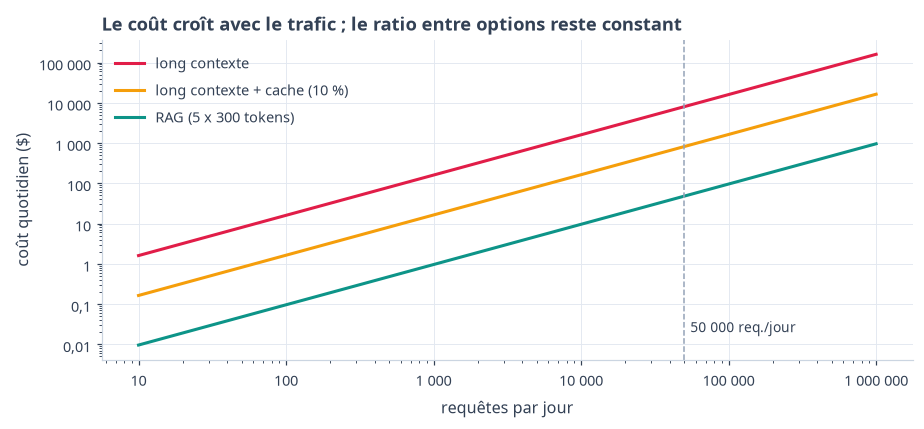

In [3]:
Rs = np.logspace(1, 6, 100)
fig, ax = plt.subplots(figsize=(8.5, 4))
for (nom, c), col in zip(lignes.items(), [ROSE, AMBER, TEAL]):
    ax.loglog(Rs, c * Rs, color=col, label=nom)
ax.axvline(R, color=GRAY, ls="--", lw=1); ax.text(R * 1.1, 2e-2, "50 000 req./jour", fontsize=9)
ax.set_xlabel("requêtes par jour"); ax.set_ylabel("coût quotidien ($)")
fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ") if v >= 1 else f"{v:g}".replace(".", ","))
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_title("Le coût croît avec le trafic ; le ratio entre options reste constant"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** À trafic élevé, le « tout dans le contexte » coûte des ordres de grandeur
> plus cher qu'un RAG (×170 ici, ×17 avec cache) et impose des secondes de pré-remplissage.
> L'indexation d'un RAG est un coût fixe, généralement négligeable.

## Exercice 6.2 : TF-IDF et BM25 à la main

**Énoncé.** Mini-corpus de 4 documents déjà tokenisés :

- D1 : « chat noir dort »
- D2 : « chat chat chat chat chat chat chat chat chat chat » (bourrage de mots-clés)
- D3 : « chien noir aboie fort la nuit dans le jardin du voisin »
- D4 : « oiseau chante »

1. Calculer l'IDF du livre ($\log N / C(t)$) des termes « chat » et « noir », puis les scores
   TF-IDF des 4 documents pour la requête « chat noir ».
2. Calculer les scores BM25 (variante Lucene, $\mathrm{IDF} = \log(1 + \frac{N - n + 0{,}5}{n + 0{,}5})$,
   $k_1 = 1{,}2$, $b = 0{,}75$).
3. Quel document gagne avec chaque méthode ? Commenter le bourrage de mots-clés.

**Rappels.** Section *Term-based retrieval* : TF-IDF $= \sum_t \mathrm{IDF}(t)\,f(t, D)$. BM25
sature la fréquence ($k_1$) et normalise par la longueur ($b$) :
$\sum_t \mathrm{IDF}(t)\,\frac{f\,(k_1+1)}{f + k_1(1 - b + b\,|D|/\mathrm{avgdl})}$.

**Solution.**

1. $N = 4$ ; « chat » est dans D1 et D2 : $\mathrm{IDF} = \log 2 \approx 0{,}693$ ; « noir »
   dans D1 et D3 : $\log 2 \approx 0{,}693$. TF-IDF : D1 $= 0{,}693 + 0{,}693 = 1{,}386$ ;
   D2 $= 10 \times 0{,}693 = 6{,}93$ ; D3 $= 0{,}693$ ; D4 $= 0$. **D2 gagne** largement.
2. Longueurs 3, 10, 11, 2 ; avgdl $= 6{,}5$. IDF Lucene pour $n = 2$ :
   $\log(1 + 2{,}5/2{,}5) = \log 2 \approx 0{,}693$. Pour D1 ($|D| = 3$) :
   $K = 1{,}2\,(0{,}25 + 0{,}75 \times 3/6{,}5) \approx 0{,}715$ ; chaque terme ($f = 1$) apporte
   $0{,}693 \times 2{,}2 / 1{,}715 \approx 0{,}889$, total $\approx 1{,}778$. Pour D2
   ($|D| = 10$, $f = 10$) : $K = 1{,}2\,(0{,}25 + 0{,}75 \times 10/6{,}5) \approx 1{,}685$ ;
   $0{,}693 \times 22 / 11{,}685 \approx 1{,}305$. Pour D3 ($|D| = 11$, « noir » seul) :
   $K \approx 1{,}823$, $0{,}693 \times 2{,}2 / 2{,}823 \approx 0{,}540$.
3. Avec BM25, **D1 gagne** (il contient les deux termes) : la saturation borne le gain du
   terme répété à $\mathrm{IDF} \times (k_1 + 1) = 1{,}52$ au plus, quel que soit $f$. Le
   TF-IDF naïf récompense linéairement la répétition, ce qui le rend vulnérable au bourrage de
   mots-clés (une technique historique de « référencement abusif »). $\blacksquare$

In [4]:
mini = [["chat", "noir", "dort"], ["chat"] * 10, "chien noir aboie fort la nuit dans le jardin du voisin".split(), ["oiseau", "chante"]]
q = ["chat", "noir"]
tfidf = c6.TfIdf(mini).scores(q)
bm = c6.BM25(mini, k1=1.2, b=0.75, variant="lucene").scores(q)
okapi = c6.BM25(mini, k1=1.2, b=0.75).scores(q)
ref = BM25Okapi(mini, k1=1.2, b=0.75).get_scores(q)
pd.DataFrame({"TF-IDF (livre)": tfidf, "BM25 Lucene": bm, "BM25 Okapi (maison)": okapi, "rank_bm25": ref},
             index=["D1", "D2", "D3", "D4"]).round(3)

,TF-IDF (livre),BM25 Lucene,BM25 Okapi (maison),rank_bm25
D1,1.386,1.778,0.0,0.0
D2,6.931,1.305,0.0,0.0
D3,0.693,0.540,0.0,0.0
D4,0.000,0.000,0.0,0.0


**Vérification.** Les valeurs calculées à la main sont retrouvées. Remarque instructive : avec
la variante Okapi, l'IDF de « chat » et de « noir » vaut $\log(2{,}5/2{,}5) = 0$, car chacun
figure dans exactement la moitié des documents. Elle n'est pas négative, donc `rank_bm25` ne
la remplace pas : **tous les scores sont nuls** et la recherche ne départage rien. C'est un
piège des tout petits corpus (ou des termes très fréquents), que la variante Lucene, toujours
positive, évite. Traçons l'effet de la répétition.

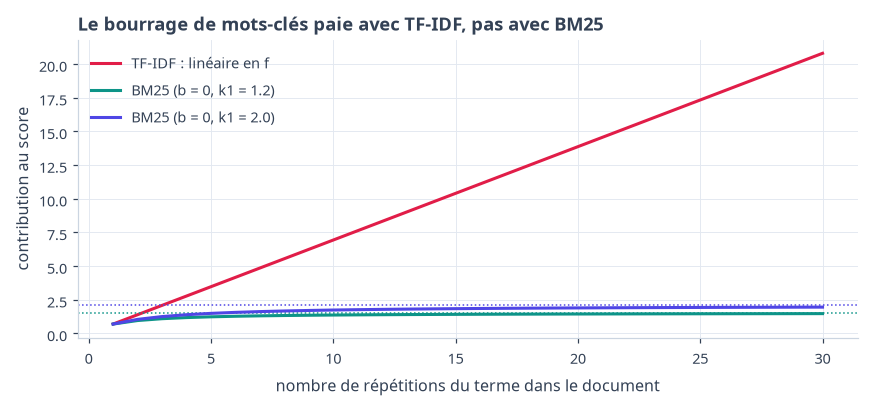

In [5]:
f = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(f, np.log(2) * f, color=ROSE, label="TF-IDF : linéaire en f")
for k1, col in [(1.2, TEAL), (2.0, INDIGO)]:
    ax.plot(f, np.log(2) * f * (k1 + 1) / (f + k1), color=col, label=f"BM25 (b = 0, k1 = {k1})")
    ax.axhline(np.log(2) * (k1 + 1), color=col, ls=":", lw=1)
ax.set_xlabel("nombre de répétitions du terme dans le document"); ax.set_ylabel("contribution au score")
ax.set_title("Le bourrage de mots-clés paie avec TF-IDF, pas avec BM25"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** TF-IDF naïf : un terme répété $f$ fois compte $f$ fois. BM25 borne cette
> contribution à $\mathrm{IDF}\,(k_1 + 1)$ et pénalise les documents longs : il est plus robuste
> aux répétitions et au bourrage.

## Exercice 6.3 : Dimensionner un index vectoriel

**Énoncé.** On indexe $N = 5 \cdot 10^7$ passages avec des embeddings de dimension $d = 768$.

1. Mémoire d'un index exact en float32, puis en float16.
2. Avec une quantification par produit (PQ) à $m = 96$ sous-vecteurs codés sur 8 bits ?
3. Avec IVF à $n_{\text{list}} = 2^{16}$ cellules et `nprobe` = 32 : nombre moyen de vecteurs
   par cellule et nombre de distances calculées par requête, comparé à la force brute.
4. HNSW stocke en plus environ $2M$ voisins (entiers de 4 octets) par vecteur dans la couche
   basse. Surcoût mémoire pour $M = 32$ ?
5. Vérifier les formules de mémoire à petite échelle avec FAISS.

**Rappels.** Section *Embedding-based retrieval* : IVF regroupe les vecteurs par k-means et ne
visite que les cellules proches ; PQ découpe chaque vecteur en sous-vecteurs remplacés par
l'indice d'un centroïde ; HNSW est un graphe hiérarchique de voisinage.

**Solution.**

1. float32 : $4Nd = 4 \times 5\cdot10^7 \times 768 \approx 1{,}54 \cdot 10^{11}$ octets
   $\approx 154$ Go ; float16 : 77 Go.
2. PQ : $m = 96$ octets par vecteur, soit $4{,}8$ Go (compression ×32), plus les livres de
   codes, négligeables ($96 \times 256 \times 8 \times 4$ octets $\approx 0{,}8$ Mo).
3. $5\cdot10^7 / 65\,536 \approx 763$ vecteurs par cellule (dans la fourchette 100 à 10 000
   citée par le livre). Distances par requête : $65\,536$ centroïdes $+ 32 \times 763 \approx
   90\,000$, contre $5 \cdot 10^7$ en force brute : environ **550 fois moins**.
4. $2M \times 4 = 256$ octets par vecteur, soit $12{,}8$ Go de plus, à ajouter aux 154 Go des
   vecteurs : HNSW est rapide mais gourmand. $\blacksquare$

In [6]:
N, d = 5e7, 768
nlist, nprobe = 2 ** 16, 32
memo = pd.Series({"Flat float32": 4 * N * d, "Flat float16": 2 * N * d, "PQ (m = 96)": 96 * N,
                  "HNSW (M = 32), graphe seul": 2 * 32 * 4 * N, "HNSW (M = 32), total": 4 * N * d + 2 * 32 * 4 * N}) / 1e9
print(memo.round(1).to_string(), "\n")
print(f"IVF : {N / nlist:.0f} vecteurs par cellule ; {nlist + nprobe * N / nlist:,.0f} distances / requête "
      f"(force brute : {N:,.0f}, gain x{N / (nlist + nprobe * N / nlist):.0f})".replace(",", " "))

Flat float32                  153.6
Flat float16                   76.8
PQ (m = 96)                     4.8
HNSW (M = 32), graphe seul     12.8
HNSW (M = 32), total          166.4 

IVF : 763 vecteurs par cellule ; 89 950 distances / requête (force brute : 50 000 000  gain x556)


**Vérification** à petite échelle : on construit les index sur $n = 20\,000$ vecteurs de
dimension 768 et on compare leur taille sérialisée aux formules.

               mesuré (Mo)  formule (Mo)
Flat                  61.4          61.4
PQ (m = 96)            2.7           2.7
HNSW (M = 32)         66.9          66.6


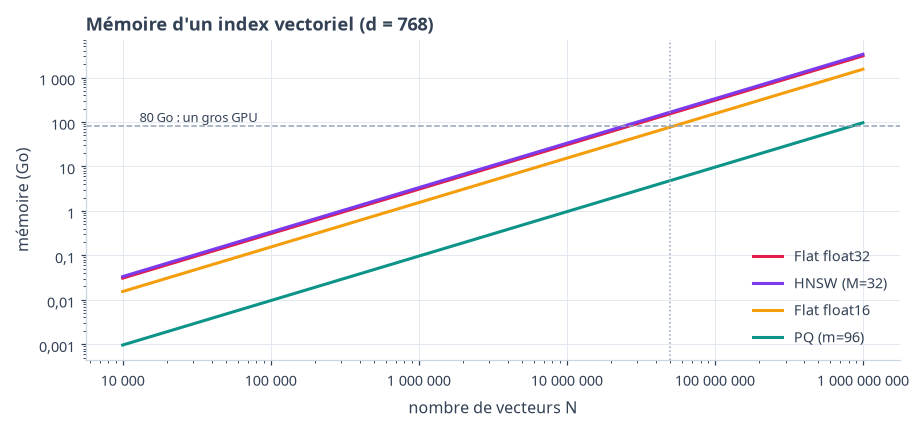

In [7]:
rng = np.random.default_rng(0)
n_, d_ = 20_000, 768
X = rng.normal(size=(n_, d_)).astype("float32")
faiss.omp_set_num_threads(8)
flat = faiss.IndexFlatL2(d_); flat.add(X)
pq = faiss.IndexPQ(d_, 96, 8); pq.train(X); pq.add(X)
hnsw = faiss.IndexHNSWFlat(d_, 32); hnsw.add(X)
mes = pd.DataFrame({
    "mesuré (Mo)": [len(faiss.serialize_index(i_)) / 1e6 for i_ in (flat, pq, hnsw)],
    "formule (Mo)": [4 * n_ * d_ / 1e6, (96 * n_ + 96 * 256 * (d_ // 96) * 4) / 1e6, (4 * n_ * d_ + 2 * 32 * 4 * n_) / 1e6]},
    index=["Flat", "PQ (m = 96)", "HNSW (M = 32)"])
print(mes.round(1))
Ns = np.logspace(4, 9, 50)
fig, ax = plt.subplots(figsize=(8.5, 4))
for nom, per, col in [("Flat float32", 4 * d, ROSE), ("HNSW (M=32)", 4 * d + 256, VIOLET), ("Flat float16", 2 * d, AMBER), ("PQ (m=96)", 96, TEAL)]:
    ax.loglog(Ns, Ns * per / 1e9, color=col, label=nom)
ax.axhline(80, color=GRAY, ls="--", lw=1); ax.text(1.3e4, 100, "80 Go : un gros GPU", fontsize=8.5, color=SLATE)
ax.axvline(N, color=GRAY, ls=":", lw=1)
ax.set_xlabel("nombre de vecteurs N"); ax.set_ylabel("mémoire (Go)")
fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ") if v >= 1 else f"{v:g}".replace(".", ","))
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_title("Mémoire d'un index vectoriel (d = 768)"); ax.legend()
plt.tight_layout(); plt.show()

Les mesures collent aux formules, à quelques métadonnées près. À $n = 20\,000$, les livres de
codes de PQ (0,8 Mo, inclus dans la formule) pèsent encore autant que la moitié des codes ; à
50 millions de vecteurs, ils deviennent négligeables. Pour HNSW, les couches supérieures du
graphe ajoutent très peu.

> **À retenir.** Mémoire d'un index exact : $4Nd$ octets. PQ compresse d'un facteur
> $4d/m$ ; IVF divise le calcul par environ $N / (n_{\text{list}} + \text{nprobe}\,N/n_{\text{list}})$ ;
> HNSW ajoute environ $8M$ octets par vecteur pour le graphe.